# Seven-day trajectory to outbreak warnings

Reuse Notebook35 daily predictions. Keep the original three-day-smoothed event definition. Compare future1–3day and1–7day warning tasks on common daily forecast dates. Calibrate both through Aug24, targets ending by Aug31. Assess Sep1–Dec24 2020. No new model training, later-year data or threshold tuning on assessment. Primary comparison: horizon-specific event recall and warning precision, with explicit event denominators. Common-event recall is supplementary and reported separately. Lead time and AP are also saved. Wider warning windows define a different task.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if (ROOT/"Weikun").is_dir():ROOT=ROOT/"Weikun"
OUTPUT=ROOT/"mentor_followup_outputs"/"2026-11-04"/"seven_day_warnings"
print(OUTPUT.resolve())

In [2]:
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score,precision_recall_curve

def event_labels(counts):
    """Causal labels; onset is confirmation, never backdated."""
    s=pd.Series(np.asarray(counts,dtype=float))
    ma=s.rolling(3,min_periods=3).mean()
    hist=ma.shift(3).rolling(28,min_periods=28)
    mean,sd=hist.mean(),hist.std(ddof=1)
    threshold=mean+2*sd
    qualify=(ma>threshold)&(s.rolling(3).sum()>=5)&threshold.notna()
    valid=threshold.notna().to_numpy()
    # Smooth continuous excess with the same sign as the two qualification gates.
    scale=np.maximum(sd.to_numpy(),1.)
    margin=np.minimum((ma.to_numpy()-threshold.to_numpy())/scale,
                      (s.rolling(3).sum().to_numpy()-5+1e-9)/(3*scale))
    active=np.zeros(len(s),bool);onset=np.zeros(len(s),bool)
    in_event=False;off=0
    for k in range(len(s)):
        if in_event:
            off=0 if qualify.iloc[k] else off+1
            if off>=7:in_event=False;off=0
        elif k>0 and qualify.iloc[k] and qualify.iloc[k-1]:
            in_event=True;onset[k]=True
        active[k]=in_event
    return dict(ma=ma.to_numpy(),threshold=threshold.to_numpy(),sd=sd.to_numpy(),
                qualify=qualify.to_numpy(),valid=valid,margin=margin,active=active,onset=onset)


NAMES=['Dynamic Panel FE','XGBoost','Random Forest']

def score_paths(counts,pos,pred):
    H=pred.shape[2];scores=np.empty((len(counts),len(pos)));margins_saved=[]
    for j,k in enumerate(pos):
        hist=counts[:,k-32:k+1];seq=np.concatenate([hist,pred[:,j,:]],axis=1)
        means=np.full(seq.shape,np.nan);means[:,2:]=(seq[:,2:]+seq[:,1:-1]+seq[:,:-2])/3
        margins=[]
        for d in range(32,33+H):
            baseline=means[:,d-30:d-2];assert baseline.shape[1]==28 and np.isfinite(baseline).all()
            mu=baseline.mean(axis=1);sd=baseline.std(axis=1,ddof=1);scale=np.maximum(sd,1.)
            margins.append(np.minimum((means[:,d]-mu-2*sd)/scale,(seq[:,d-2:d+1].sum(axis=1)-5+1e-9)/(3*scale)))
        margins=np.stack(margins,axis=1)
        scores[:,j]=np.max(np.minimum(margins[:,:-1],margins[:,1:]),axis=1)
        if j in [0,len(pos)//2,len(pos)-1]:
            for z in [0,100,len(counts)-1]:assert np.allclose(margins[z],event_labels(seq[z])['margin'][-(H+1):])
    assert np.isfinite(scores).all();return scores

def evaluate(score,eligible,onsets,forecast_dates,calendar,threshold,H):
    alarms=[];events=[]
    for z in range(len(score)):
        ed=calendar[onsets[z]]
        covered=[d for d in ed if np.any(eligible[z]&((d-forecast_dates).astype('timedelta64[D]').astype(int)>=1)&((d-forecast_dates).astype('timedelta64[D]').astype(int)<=H))]
        matched=set();last=None
        for j,d in enumerate(forecast_dates):
            if not eligible[z,j] or not score[z,j]>threshold:continue
            if last is not None and int((d-last)/np.timedelta64(1,'D'))<7:continue
            last=d;candidates=[e for e in covered if e not in matched and 1<=int((e-d)/np.timedelta64(1,'D'))<=H]
            e=min(candidates) if candidates else None
            if e is not None:matched.add(e)
            alarms.append(dict(region_index=z,daily_forecast_date=str(d),matched_event_date=str(e) if e is not None else '',true_warning=e is not None,lead_days=float((e-d)/np.timedelta64(1,'D')) if e is not None else np.nan))
        for e in covered:events.append(dict(region_index=z,event_date=str(e),detected=e in matched))
    a=pd.DataFrame(alarms,columns=['region_index','daily_forecast_date','matched_event_date','true_warning','lead_days']);ev=pd.DataFrame(events,columns=['region_index','event_date','detected'])
    tp=int(a.true_warning.sum());fp=len(a)-tp
    assert tp==int(ev.detected.sum())
    met=dict(eligible_events=len(ev),detected_events=tp,warning_episodes=len(a),false_warning_episodes=fp,event_detection_rate=tp/len(ev) if len(ev) else np.nan,warning_precision=tp/len(a) if len(a) else np.nan,mean_lead_days=a.lead_days.mean(),median_lead_days=a.lead_days.median(),false_warnings_per_30_at_risk_zip_days=fp*30/eligible.sum(),at_risk_zip_days=int(eligible.sum()))
    return met,a,ev

def run_warning_horizons(root,output):
    root=Path(root);out=Path(output);out.mkdir(parents=True,exist_ok=True);(out/'figures').mkdir(exist_ok=True)
    seven=root/'mentor_followup_outputs/2026-11-04/seven_day_trajectory'
    if not (seven/'predictions_Dynamic_7day.npz').exists():raise FileNotFoundError('Run Notebook35 or restore its local seven-day prediction files. They are excluded from Git.')
    datasets=[]
    for name in NAMES:
        with np.load(seven/f'predictions_{name.split()[0]}_7day.npz') as z:datasets.append({k:z[k].copy() for k in z.files})
    ids=datasets[0]['zip'];fd=datasets[0]['daily_forecast_dates'].astype('datetime64[D]')
    for d in datasets:
        for k in ['zip','daily_forecast_dates','actual_cases']:assert np.array_equal(d[k],datasets[0][k]),k
    f=pd.read_csv(root/'rolling_trajectory_outputs/inputs/nj_daily_features.csv.gz',usecols=['zip','date','cases_today'],dtype={'zip':str},parse_dates=['date'])
    f=f[f.zip.isin(ids)&f.date.between('2020-01-01','2020-12-31')]
    pivot=f.pivot(index='zip',columns='date',values='cases_today').reindex(ids);calendar=pivot.columns.to_numpy().astype('datetime64[D]');counts=pivot.to_numpy();pos=np.searchsorted(calendar,fd)
    assert np.isfinite(counts).all();assert np.array_equal(np.stack([counts[:,pos+h] for h in range(1,8)],axis=-1),datasets[0]['actual_cases'])
    labs=[event_labels(x) for x in counts];onsets=np.stack([x['onset'] for x in labs]);active=np.stack([x['active'] for x in labs]);valid=np.stack([x['valid'] for x in labs]);eligible=(~active[:,pos])&valid[:,pos]
    calibration=fd<=np.datetime64('2020-08-24');assessment=fd>=np.datetime64('2020-09-01');assert fd[calibration].max()+np.timedelta64(7,'D')<np.datetime64('2020-09-01')
    grid=[];rows=[];evs={};als={};curves=[];verification=[]
    for model,d in zip(NAMES,datasets):
        for H in [3,7]:
            score=score_paths(counts,pos,np.maximum(d['predictions'][:,:,:H],0))
            if H==3:
                old=pd.read_csv(root/'outbreak_task_outputs/case_surge_v1_20261101'/(model.lower().replace(' ','_')+'_risk_scores.csv.gz'),dtype={'zip':str})
                old=old.pivot(index='zip',columns='forecast_origin',values='risk_score').reindex(index=ids,columns=pd.to_datetime(fd).strftime('%Y-%m-%d'))
                assert np.allclose(score,old.to_numpy(),atol=1e-7), 'Three-day risk must reproduce original'
            choices=[]
            for q in [0,.25,.5,1,2,3,5,10,np.inf]:
                met,_,_=evaluate(score[:,calibration],eligible[:,calibration],onsets,fd[calibration],calendar,q,H)
                choices.append(dict(model=model,horizon_days=H,threshold=q,**met))
            chosen=min([c for c in choices if c['false_warnings_per_30_at_risk_zip_days']<=1],key=lambda c:c['threshold']);grid.extend(choices)
            future=np.stack([onsets[:,pos+h] for h in range(1,H+1)],axis=-1).any(axis=-1)
            for phase,mask in [('calibration',calibration),('assessment',assessment)]:
                met,a,ev=evaluate(score[:,mask],eligible[:,mask],onsets,fd[mask],calendar,chosen['threshold'],H)
                y=future[:,mask][eligible[:,mask]];sc=score[:,mask][eligible[:,mask]]
                ap=average_precision_score(y,sc)
                rows.append(dict(model=model,horizon_days=H,phase=phase,threshold=chosen['threshold'],AP=ap,positive_zip_date_share=y.mean(),forecast_dates=int(mask.sum()),**met))
                if phase=='assessment':
                    evs[(model,H)]=ev;als[(model,H)]=a
                    a['zip']=a.region_index.map(dict(enumerate(ids)));ev['zip']=ev.region_index.map(dict(enumerate(ids)))
                    slug=model.split()[0]+f'_{H}day';a.to_csv(out/(slug+'_warning_episodes.csv'),index=False);ev.to_csv(out/(slug+'_event_detection.csv'),index=False)
                    pr,re,_=precision_recall_curve(y,sc);curves.append((model,H,pr,re,ap))
            pd.DataFrame(dict(zip=np.repeat(ids,len(fd)),daily_forecast_date=np.tile(fd,len(ids)),eligible=eligible.ravel(),risk_score=score.ravel(),event_within_horizon=future.ravel())).to_csv(out/(model.split()[0]+f'_{H}day_risk.csv.gz'),index=False,compression='gzip')
    result=pd.DataFrame(rows)
    # Event recall on a shared catalog. Matching still uses the full native horizon;
    # precision remains for each explicitly different warning horizon.
    event_sets=[set(map(tuple,e[['region_index','event_date']].to_numpy())) for e in evs.values()];common=set.intersection(*event_sets)
    result['common_eligible_events']=np.nan;result['common_detected_events']=np.nan;result['common_event_detection_rate']=np.nan
    for (model,H),ev in evs.items():
        cm=np.array([(z,t) in common for z,t in ev[['region_index','event_date']].to_numpy()]);tp=int(ev.loc[cm,'detected'].sum());ix=(result.model==model)&(result.horizon_days==H)&(result.phase=='assessment');result.loc[ix,['common_eligible_events','common_detected_events','common_event_detection_rate']]=[len(common),tp,tp/len(common)]
    result.to_csv(out/'warning_horizon_metrics.csv',index=False);pd.DataFrame(grid).to_csv(out/'threshold_calibration.csv',index=False)
    pd.DataFrame(sorted(common),columns=['region_index','event_date']).assign(zip=lambda x:x.region_index.map(dict(enumerate(ids)))).to_csv(out/'common_event_catalog.csv',index=False)
    a=result.query("phase=='assessment'");diff=[]
    for model in NAMES:
        g=a[a.model==model].set_index('horizon_days');diff.append(dict(model=model,detection_change_pp=100*(g.loc[7,'event_detection_rate']-g.loc[3,'event_detection_rate']),common_event_detection_change_pp=100*(g.loc[7,'common_event_detection_rate']-g.loc[3,'common_event_detection_rate']),precision_change_pp=100*(g.loc[7,'warning_precision']-g.loc[3,'warning_precision']),AP_change=g.loc[7,'AP']-g.loc[3,'AP'],mean_lead_change=g.loc[7,'mean_lead_days']-g.loc[3,'mean_lead_days'],extra_false_warnings=int(g.loc[7,'false_warning_episodes']-g.loc[3,'false_warning_episodes'])))
    pd.DataFrame(diff).to_csv(out/'seven_minus_three.csv',index=False)
    leads=[]
    for (model,H),al in als.items():
        for k in range(1,H+1):leads.append(dict(model=model,horizon_days=H,lead_days=k,detected_events=int((al.lead_days==k).sum()),share_of_detected=float((al.lead_days==k).sum()/al.true_warning.sum())))
    pd.DataFrame(leads).to_csv(out/'lead_time_distribution.csv',index=False)
    plt.rcParams.update({'font.family':'Arial','font.size':12,'axes.spines.top':False,'axes.spines.right':False,'text.color':'#173654','xtick.color':'#173654','ytick.color':'#173654'})
    from matplotlib.ticker import PercentFormatter
    fig,axs=plt.subplots(1,2,figsize=(12,4.3));x=np.arange(3);w=.34
    for ax,col,title in zip(axs,['event_detection_rate','warning_precision'],['Detected events / horizon-eligible events','Correct warnings / issued warnings']):
        for j,H in enumerate([3,7]):
            values=a[a.horizon_days==H].set_index('model').reindex(NAMES)[col];b=ax.bar(x+(j-.5)*w,values,w,label=f'Next {H} days',color=['#64748B','#2563EB'][j]);ax.bar_label(b,labels=[f'{v:.1%}' for v in values],padding=4,fontsize=11,fontweight='bold')
        ax.set(xticks=x,xticklabels=['Dynamic Panel','XGBoost','Random Forest'],ylim=(0,1.15),title=title);ax.set_yticks(np.arange(0,1.01,.2));ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend(loc='upper left',ncol=2,fontsize=10);ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
    fig.tight_layout();fig.savefig(out/'figures/three_vs_seven_warnings.png',dpi=220);plt.close(fig)
    fig,ax=plt.subplots(figsize=(9,4))
    for model,H,pr,re,ap in curves:ax.plot(re,pr,label=f'{model}, {H}d AP={ap:.3f}',linestyle='-' if H==7 else '--')
    ax.set(xlabel='Recall across eligible ZIP-dates',ylabel='Precision',title='Horizon-specific risk ranking (different positive labels)');ax.legend(fontsize=8);fig.tight_layout();fig.savefig(out/'figures/PR_horizons.png',dpi=200);plt.close(fig)
    protocol=dict(regions=len(ids),common_forecast_dates=len(fd),calibration_last_forecast_date=str(fd[calibration].max()),calibration_targets_end='2020-08-31',assessment_first_forecast_date=str(fd[assessment].min()),assessment_last_forecast_date=str(fd[assessment].max()),assessment_dates=int(assessment.sum()),common_events=len(common),case_surge_definition='Original MA3 > 28-earlier-MA3 mean +2SD; sum3>=5; two consecutive days; reset after7 nonqualifying days',warning_horizons=[3,7],cooldown_days=7,threshold_rule='Original fixed nonnegative grid; smallest satisfying calibration false-alert criterion<=1 per30 at-risk ZIPdays',new_model_training=False,causality='Issued predictions plus actual history through forecast date only; risk uses no future actual values',three_day_risk_reproduced=True,interpretation='Changing horizon changes label prevalence and matching opportunity. Common-event recall uses intersection of eligible event catalogs; precision uses each native1..H-day matching. No untouched test or significance claim. Onset-date replay does not establish real-time availability.')
    (out/'protocol.json').write_text(json.dumps(protocol,indent=2,default=lambda x:int(x) if isinstance(x,np.integer) else float(x)),encoding='utf-8')
    (out/'RESULTS.md').write_text('# Three versus seven day warning assessment\n\n'+a.round(5).to_markdown(index=False)+'\n\n## Seven minus three\n\n'+pd.DataFrame(diff).round(5).to_markdown(index=False)+'\n\n'+json.dumps(protocol,indent=2)+'\n\nEvent definition remains MA3; seven refers to forecast/warning horizon, not seven-day smoothing. Same common daily forecast dates. The original published three-day numbers used a different calibration end date and four extra late-December origins; use the matched values here. Wider event windows make matching easier and change the target; a better recall is not proof of a better same-horizon forecasting model. AP across horizons uses different positive labels. Lead includes detected events only; missed events and false alerts must be considered. Warnings may follow already visible abnormal activity.\n',encoding='utf-8')
    print(a[['model','horizon_days','eligible_events','common_eligible_events','common_event_detection_rate','warning_precision','mean_lead_days','AP']].to_string(index=False));return result,pd.DataFrame(diff)


In [3]:
metrics,changes=run_warning_horizons(ROOT,OUTPUT)
display(metrics.query("phase == 'assessment'").round(4))
display(changes.round(4))

           model  horizon_days  eligible_events  common_eligible_events  common_event_detection_rate  warning_precision  mean_lead_days       AP
Dynamic Panel FE             3             1039                  1039.0                     0.789220           0.667209        1.319512 0.523548
Dynamic Panel FE             7             1125                  1039.0                     0.882579           0.568773        2.028322 0.368996
         XGBoost             3             1039                  1039.0                     0.732435           0.828976        1.135348 0.544197
         XGBoost             7             1125                  1039.0                     0.762271           0.855448        1.327869 0.486082
   Random Forest             3             1039                  1039.0                     0.799808           0.757521        1.238267 0.543377
   Random Forest             7             1125                  1039.0                     0.854668           0.767703        1.6

,model,horizon_days,phase,threshold,AP,positive_zip_date_share,forecast_dates,eligible_events,detected_events,warning_episodes,false_warning_episodes,event_detection_rate,warning_precision,mean_lead_days,median_lead_days,false_warnings_per_30_at_risk_zip_days,at_risk_zip_days,common_eligible_events,common_detected_events,common_event_detection_rate
1,Dynamic Panel FE,3,assessment,0,0.5235,0.0568,115,1039,820,1229,409,0.7892,0.6672,1.3195,1.0,0.2296,53430,1039.0,820.0,0.7892
3,Dynamic Panel FE,7,assessment,0,0.3690,0.1284,115,1125,918,1614,696,0.8160,0.5688,2.0283,1.0,0.3908,53430,1039.0,917.0,0.8826
5,XGBoost,3,assessment,0,0.5442,0.0568,115,1039,761,918,157,0.7324,0.8290,1.1353,1.0,0.0882,53430,1039.0,761.0,0.7324
7,XGBoost,7,assessment,0,0.4861,0.1284,115,1125,793,927,134,0.7049,0.8554,1.3279,1.0,0.0752,53430,1039.0,792.0,0.7623
9,Random Forest,3,assessment,0,0.5434,0.0568,115,1039,831,1097,266,0.7998,0.7575,1.2383,1.0,0.1494,53430,1039.0,831.0,0.7998
11,Random Forest,7,assessment,0,0.4890,0.1284,115,1125,889,1158,269,0.7902,0.7677,1.6490,1.0,0.1510,53430,1039.0,888.0,0.8547


,model,detection_change_pp,common_event_detection_change_pp,precision_change_pp,AP_change,mean_lead_change,extra_false_warnings
0,Dynamic Panel FE,2.6780,9.3359,-9.8436,-0.1546,0.7088,287
1,XGBoost,-2.7546,2.9836,2.6472,-0.0581,0.1925,-23
2,Random Forest,-0.9585,5.4860,1.0182,-0.0544,0.4108,3


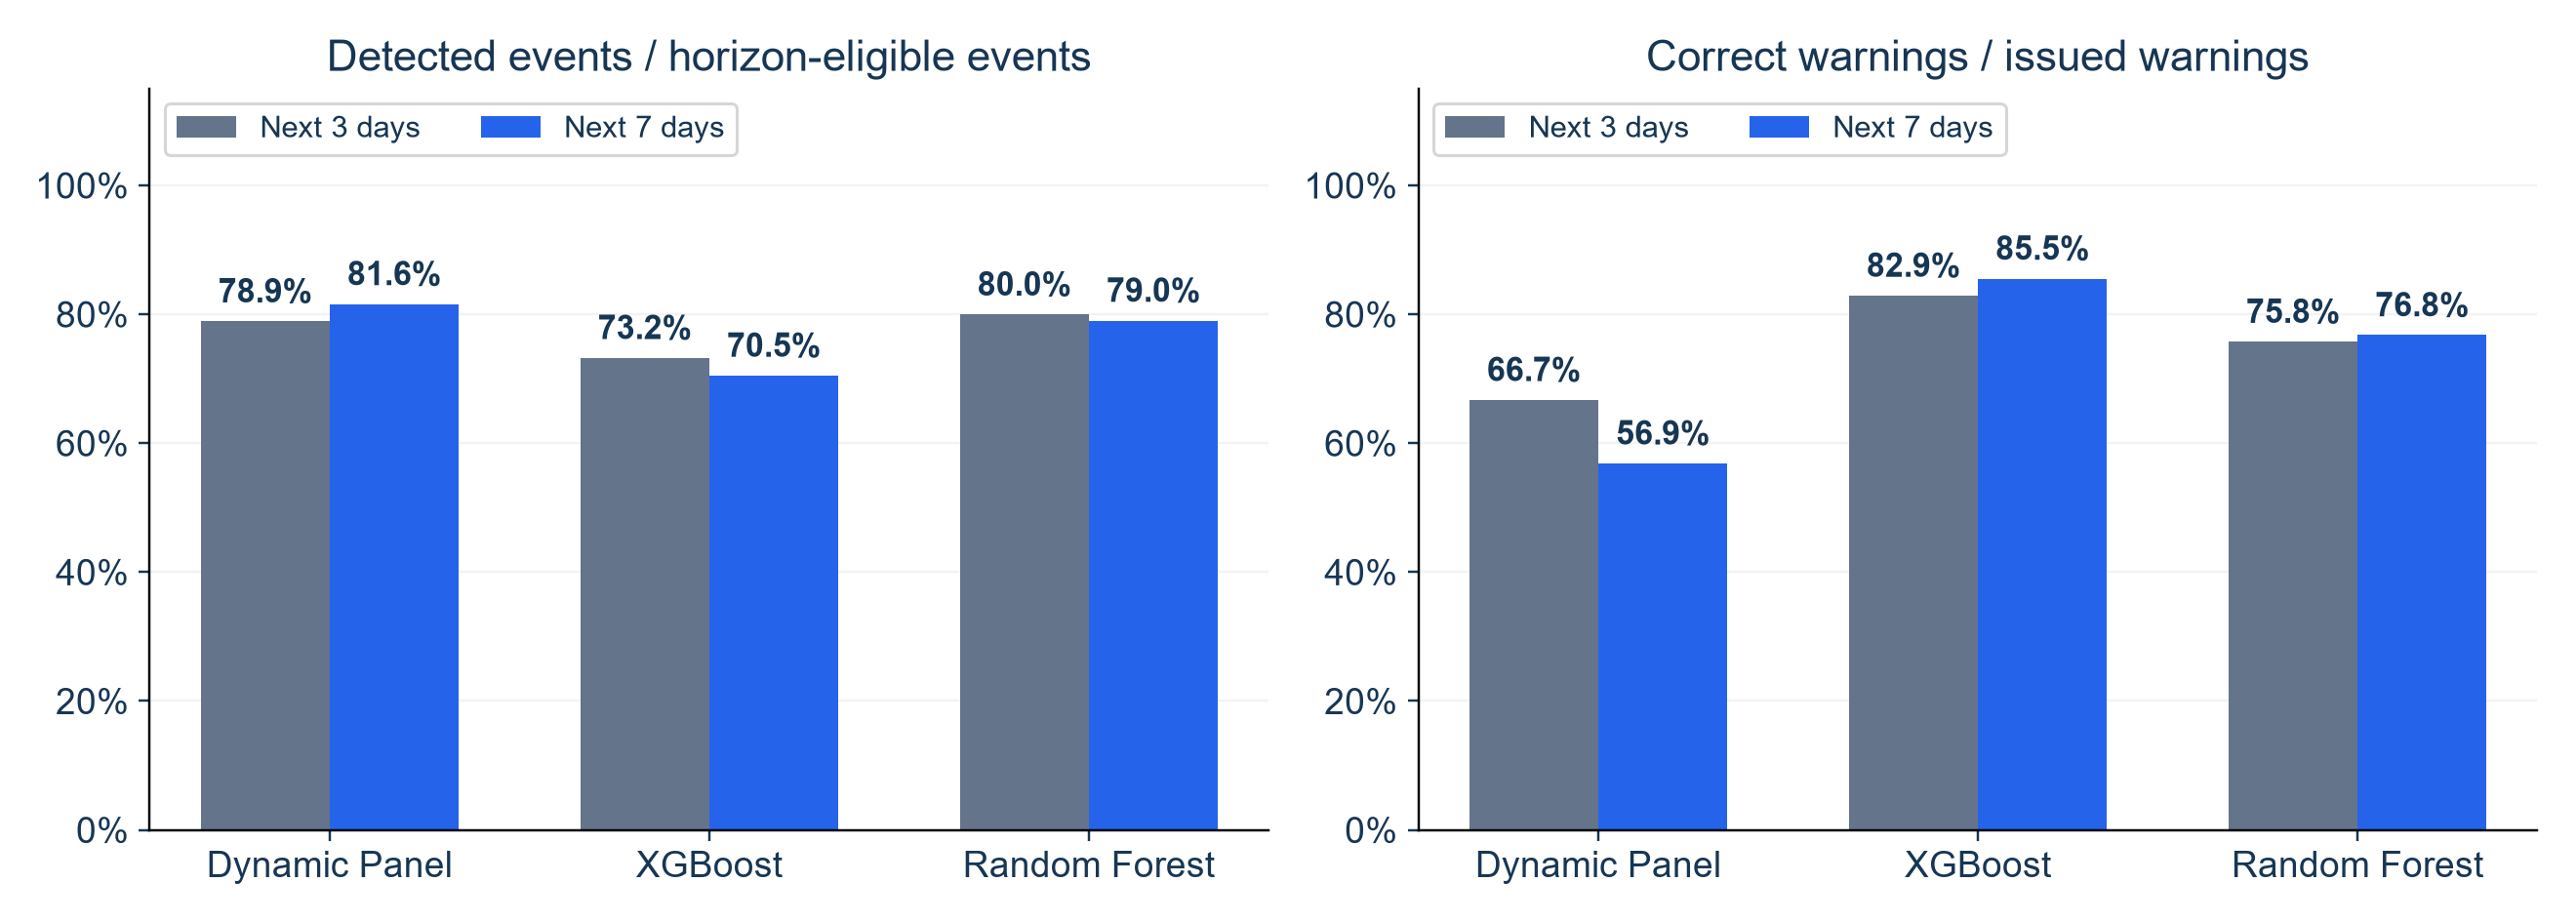

,model,horizon_days,lead_days,detected_events,share_of_detected
0,Dynamic Panel FE,3,1,600,0.7317
1,Dynamic Panel FE,3,2,178,0.2171
2,Dynamic Panel FE,3,3,42,0.0512
3,Dynamic Panel FE,7,1,553,0.6024
4,Dynamic Panel FE,7,2,162,0.1765
5,Dynamic Panel FE,7,3,55,0.0599
6,Dynamic Panel FE,7,4,35,0.0381
7,Dynamic Panel FE,7,5,38,0.0414
8,Dynamic Panel FE,7,6,35,0.0381
9,Dynamic Panel FE,7,7,40,0.0436


# Three versus seven day warning assessment

| model            |   horizon_days | phase      |   threshold |      AP |   positive_zip_date_share |   forecast_dates |   eligible_events |   detected_events |   warning_episodes |   false_warning_episodes |   event_detection_rate |   warning_precision |   mean_lead_days |   median_lead_days |   false_warnings_per_30_at_risk_zip_days |   at_risk_zip_days |   common_eligible_events |   common_detected_events |   common_event_detection_rate |
|:-----------------|---------------:|:-----------|------------:|--------:|--------------------------:|-----------------:|------------------:|------------------:|-------------------:|-------------------------:|-----------------------:|--------------------:|-----------------:|-------------------:|-----------------------------------------:|-------------------:|-------------------------:|-------------------------:|------------------------------:|
| Dynamic Panel FE |              3 | assessment |           0 | 0.52355 |                   0.05682 |              115 |              1039 |               820 |               1229 |                      409 |                0.78922 |             0.66721 |          1.31951 |                  1 |                                  0.22965 |              53430 |                     1039 |                      820 |                       0.78922 |
| Dynamic Panel FE |              7 | assessment |           0 | 0.369   |                   0.12843 |              115 |              1125 |               918 |               1614 |                      696 |                0.816   |             0.56877 |          2.02832 |                  1 |                                  0.39079 |              53430 |                     1039 |                      917 |                       0.88258 |
| XGBoost          |              3 | assessment |           0 | 0.5442  |                   0.05682 |              115 |              1039 |               761 |                918 |                      157 |                0.73244 |             0.82898 |          1.13535 |                  1 |                                  0.08815 |              53430 |                     1039 |                      761 |                       0.73244 |
| XGBoost          |              7 | assessment |           0 | 0.48608 |                   0.12843 |              115 |              1125 |               793 |                927 |                      134 |                0.70489 |             0.85545 |          1.32787 |                  1 |                                  0.07524 |              53430 |                     1039 |                      792 |                       0.76227 |
| Random Forest    |              3 | assessment |           0 | 0.54338 |                   0.05682 |              115 |              1039 |               831 |               1097 |                      266 |                0.79981 |             0.75752 |          1.23827 |                  1 |                                  0.14935 |              53430 |                     1039 |                      831 |                       0.79981 |
| Random Forest    |              7 | assessment |           0 | 0.48901 |                   0.12843 |              115 |              1125 |               889 |               1158 |                      269 |                0.79022 |             0.7677  |          1.64904 |                  1 |                                  0.15104 |              53430 |                     1039 |                      888 |                       0.85467 |

## Seven minus three

| model            |   detection_change_pp |   common_event_detection_change_pp |   precision_change_pp |   AP_change |   mean_lead_change |   extra_false_warnings |
|:-----------------|----------------------:|-----------------------------------:|----------------------:|------------:|-------------------:|-----------------------:|
| Dynamic Panel FE |               2.67796 |                            9.3359  |              -9.84359 |    -0.15455 |            0.70881 |                    287 |
| XGBoost          |              -2.75461 |                            2.98364 |               2.64716 |    -0.05811 |            0.19252 |                    -23 |
| Random Forest    |              -0.95853 |                            5.48604 |               1.01824 |    -0.05437 |            0.41078 |                      3 |

{
  "regions": 585,
  "common_forecast_dates": 239,
  "calibration_last_forecast_date": "2020-08-24",
  "calibration_targets_end": "2020-08-31",
  "assessment_first_forecast_date": "2020-09-01",
  "assessment_last_forecast_date": "2020-12-24",
  "assessment_dates": 115,
  "common_events": 1039,
  "case_surge_definition": "Original MA3 > 28-earlier-MA3 mean +2SD; sum3>=5; two consecutive days; reset after7 nonqualifying days",
  "warning_horizons": [
    3,
    7
  ],
  "cooldown_days": 7,
  "threshold_rule": "Original fixed nonnegative grid; smallest satisfying calibration false-alert criterion<=1 per30 at-risk ZIPdays",
  "new_model_training": false,
  "causality": "Issued predictions plus actual history through forecast date only; risk uses no future actual values",
  "three_day_risk_reproduced": true,
  "interpretation": "Changing horizon changes label prevalence and matching opportunity. Common-event recall uses intersection of eligible event catalogs; precision uses each native1..H-day matching. No untouched test or significance claim. Onset-date replay does not establish real-time availability."
}

Event definition remains MA3; seven refers to forecast/warning horizon, not seven-day smoothing. Same common daily forecast dates. The original published three-day numbers used a different calibration end date and four extra late-December origins; use the matched values here. Wider event windows make matching easier and change the target; a better recall is not proof of a better same-horizon forecasting model. AP across horizons uses different positive labels. Lead includes detected events only; missed events and false alerts must be considered. Warnings may follow already visible abnormal activity.


In [4]:
from IPython.display import display,Image,Markdown
display(Image(filename=str(OUTPUT/"figures/three_vs_seven_warnings.png")))
display(pd.read_csv(OUTPUT/"lead_time_distribution.csv").round(4))
display(Markdown((OUTPUT/"RESULTS.md").read_text(encoding="utf-8")))

## Interpretation safeguards
Three-day and seven-day tasks have different eligible-event denominators. Report these explicitly. A longer matching window can turn an otherwise false warning into a correct warning without changing the case forecast. The common-event recall subset is a useful supplementary analysis but excludes events with no eligible three-day forecast opportunity. Do not interpret common-event recall as recall for the entire seven-day event catalog. AP across horizons also uses different positive labels. Neither task has established superiority on untouched testing data.